# SHAP Explainability 

**Model:** Final tuned XGBoost, delta target (`n_estimators=200, max_depth=4, learning_rate=0.01, subsample=0.6, colsample_bytree=0.6, min_child_weight=3, reg_alpha=0.1, reg_lambda=1.5`).
Fitting 5 folds for each of 50 candidates, totalling 250 fits


Best CV RMSE (on delta target): 12.889
**Important framing note:** the model predicts the *change* in PM2.5 from now to next hour, not the absolute level. This means SHAP values here explain **what drives PM2.5 to increase or decrease** - directly relevant to explaining spikes (a spike is, by definition, a large positive delta).


In [1]:
# Load data and the final tuned model

import pandas as pd
import numpy as np
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
import joblib

df = pd.read_csv("../data/processed/kathmandu_features.csv")
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
df = df.sort_values("datetime_utc").reset_index(drop=True)

horizon = 1
target_column = f"target_pm25_next_{horizon}h"
target_columns = [c for c in df.columns if c.startswith("target_")]
feature_columns = [c for c in df.columns if c not in ["datetime_utc"] + target_columns]

current_pm25 = df["pm25"]
y_absolute = df[target_column]
y_delta = y_absolute - current_pm25

valid_mask = ~y_delta.isna()
X = df.loc[valid_mask, feature_columns].reset_index(drop=True)
y_delta_valid = y_delta[valid_mask].reset_index(drop=True)
dates_valid = df.loc[valid_mask, "datetime_utc"].reset_index(drop=True)
current_pm25_valid = current_pm25[valid_mask].reset_index(drop=True)
y_absolute_valid = y_absolute[valid_mask].reset_index(drop=True)

print(f"Rows: {len(X)}, Features: {len(feature_columns)}")

# Load the final tuned model 
model = joblib.load(f"../models/xgboost_tuned_final_{horizon}h.pkl")
print("Model loaded.")

Rows: 8312, Features: 32
Model loaded.


In [2]:
# Compute SHAP values

explainer = shap.TreeExplainer(model)     # XGBoost is a tree-based model, this gives exact SHAP values efficiently
shap_values = explainer.shap_values(X)

print(f"SHAP values shape: {shap_values.shape}")  
print(f"Base value (expected delta prediction): {explainer.expected_value:.3f}")

SHAP values shape: (8312, 32)
Base value (expected delta prediction): 0.028


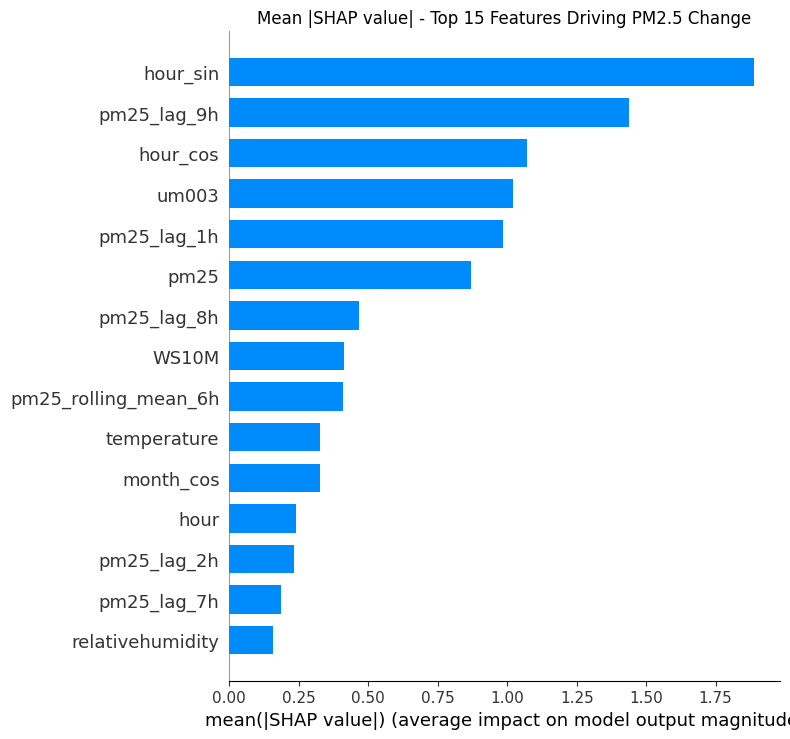

In [3]:
''' Global feature importance - SHAP summary bar plot
Mean absolute SHAP value per feature - which features matter most *on average* across all predictions, regardless of direction.'''

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X, plot_type="bar", show=False, max_display=15)
plt.title("Mean |SHAP value| - Top 15 Features Driving PM2.5 Change")
plt.tight_layout()
plt.show()

# Global feature importance : SHAP summary (beeswarm)

Shows not just which features matter, but how each dot is one prediction, color shows the feature's value (red=high, blue=low), and horizontal position shows whether that feature pushed the prediction toward an increase (right) or decrease (left) in PM2.5.

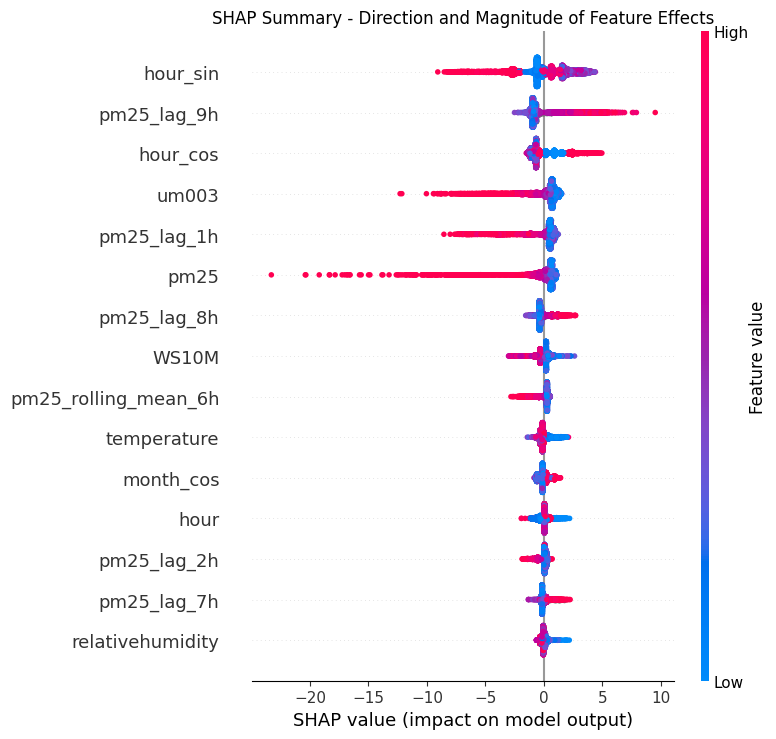

In [4]:
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X, show=False, max_display=15)
plt.title("SHAP Summary - Direction and Magnitude of Feature Effects")
plt.tight_layout()
plt.show()

In [5]:
''' Importance by feature group
SHAP values are additive, so related columns are summed into one score per group. This avoids splitting credit across correlated features (e.g. hour, hour_sin, hour_cos).'''

shap_df = pd.DataFrame(shap_values, columns=feature_columns)

groups = {
    "Recent PM2.5 (current, lags, rolling)": [c for c in feature_columns if c.startswith("pm25")],
    "Particle count (um003)": ["um003"],
    "Time of day": ["hour", "hour_sin", "hour_cos"],
    "Day of week": ["day_of_week", "is_weekend"],
    "Season": ["month", "month_sin", "month_cos"],
    "Weather": ["WS10M", "WD10M", "wind_dir_sin", "wind_dir_cos", "PRECTOTCORR", "temperature", "relativehumidity"],
    "Station / data quality": ["station_teku", "station_mid_baneshwor", "was_missing"],
}

grouped = pd.DataFrame({g: shap_df[cols].sum(axis=1) for g, cols in groups.items()})
print(grouped.abs().mean().sort_values(ascending=False))

Time of day                              2.919783
Recent PM2.5 (current, lags, rolling)    2.414527
Particle count (um003)                   1.021007
Weather                                  0.762963
Season                                   0.354274
Station / data quality                   0.023461
Day of week                              0.005382
dtype: float32


Shows how a single feature's value relates to its SHAP contribution, and highlights interaction effects with a second automatically-chosen feature 

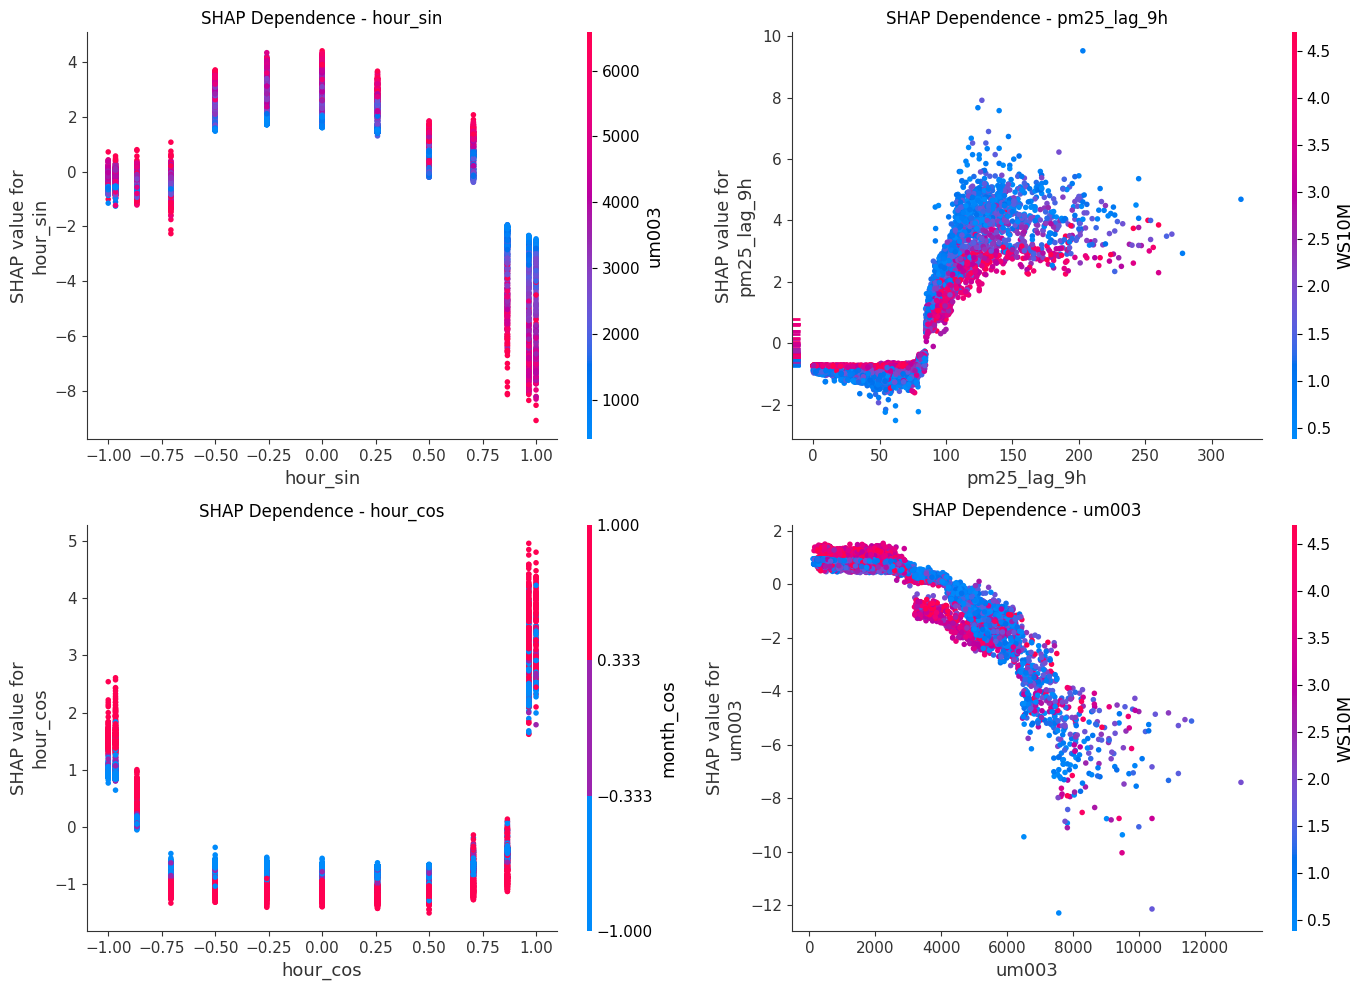

In [6]:
# Dependence plots for top features

top_features = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_columns).sort_values(ascending=False).head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, feature in zip(axes.flatten(), top_features):
    shap.dependence_plot(feature, shap_values, X, ax=ax, show=False)
    ax.set_title(f"SHAP Dependence - {feature}")
plt.tight_layout()
plt.show()

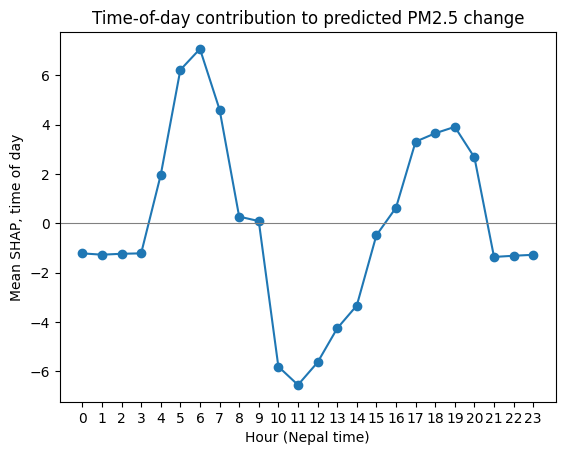

In [7]:
''' Time-of-day effect (Nepal local time)
Combined SHAP of hour, hour_sin and hour_cos, averaged per hour after converting UTC to Nepal time (UTC+05:45).'''

local_hour = (dates_valid + pd.Timedelta(hours=5, minutes=45)).dt.hour

grouped.groupby(local_hour.values)["Time of day"].mean().plot(marker="o")
plt.axhline(0, color="grey", linewidth=0.8)
plt.xticks(range(24))
plt.xlabel("Hour (Nepal time)")
plt.ylabel("Mean SHAP, time of day")
plt.title("Time-of-day contribution to predicted PM2.5 change")
plt.show()

Event: 2025-12-08 00:15:00
PM2.5 went from 79.5 to 158.0 (actual change: +78.5)
Model's predicted change: +24.0


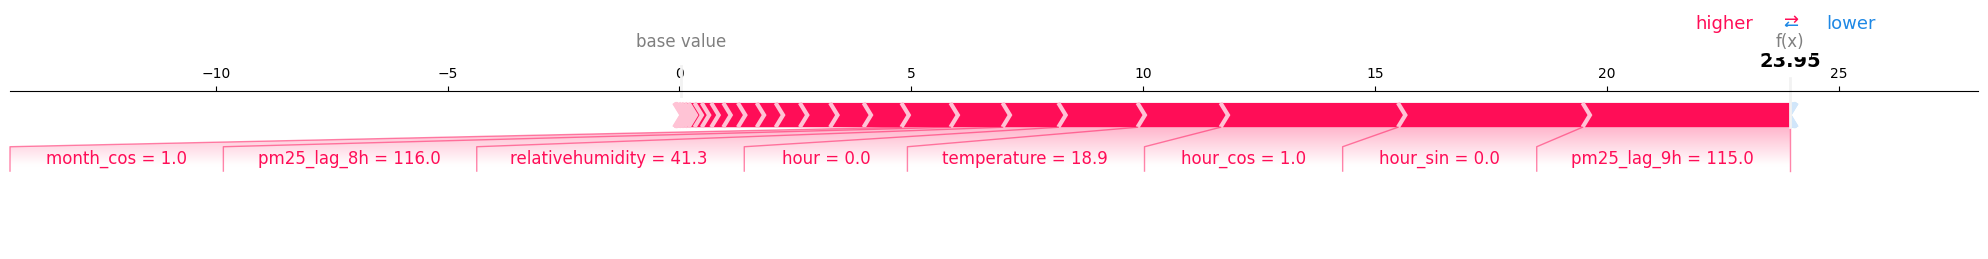

                    date  actual  predicted
4097 2026-04-02 22:15:00   190.4   3.000000
2691 2026-01-26 22:15:00   176.9  16.500000
2592 2026-01-23 02:15:00   137.0   1.500000
273  2025-11-30 20:15:00   131.8  -0.000000
2537 2026-01-21 23:15:00   130.7  19.900000
684  2025-12-09 09:15:00   126.0   2.800000
1364 2025-12-23 13:15:00   121.0  17.200001
2032 2026-01-06 23:15:00   116.2  23.000000
561  2025-12-06 20:15:00   108.7  -0.300000
2879 2026-02-03 18:15:00   106.0  -3.500000
1792 2026-01-01 23:15:00   105.8  22.900000
2813 2026-02-01 00:15:00   102.0  19.299999
2825 2026-02-01 12:15:00   101.5  14.300000
2716 2026-01-27 23:15:00    97.0  19.500000
4577 2026-04-13 11:15:00    93.0  10.100000
2696 2026-01-27 03:15:00    92.0  -2.400000
2294 2026-01-13 12:15:00    91.5  19.900000
2320 2026-01-14 14:15:00    90.0  13.800000
3751 2026-03-25 23:15:00    87.5   9.300000
522  2025-12-06 00:15:00    86.2  17.299999


In [8]:
''' Explains the hour where the model expected the biggest rise in PM2.5, then checks how well the model tracks the 20 largest real spikes.'''

# Hour the model most expected a rise
pred_delta = model.predict(X)
spike_idx = int(np.argmax(pred_delta))

print(f"Event: {dates_valid.iloc[spike_idx]}")
print(f"PM2.5 went from {current_pm25_valid.iloc[spike_idx]:.1f} to {y_absolute_valid.iloc[spike_idx]:.1f} "
      f"(actual change: {y_delta_valid.iloc[spike_idx]:+.1f})")
print(f"Model's predicted change: {pred_delta[spike_idx]:+.1f}")

shap.force_plot(
    explainer.expected_value,
    shap_values[spike_idx],
    X.iloc[spike_idx],
    matplotlib=True,
    show=False,
)
plt.tight_layout()
plt.show()

# How well does the model track real spikes?
top = y_delta_valid.nlargest(20).index
print(pd.DataFrame({"date": dates_valid[top], "actual": y_delta_valid[top],
                    "predicted": pred_delta[top]}).round(1))

Drop event: 2026-01-23 06:15:00
PM2.5 went from 203.0 to 60.9 (actual change: -142.1)
Model's predicted change: -56.4


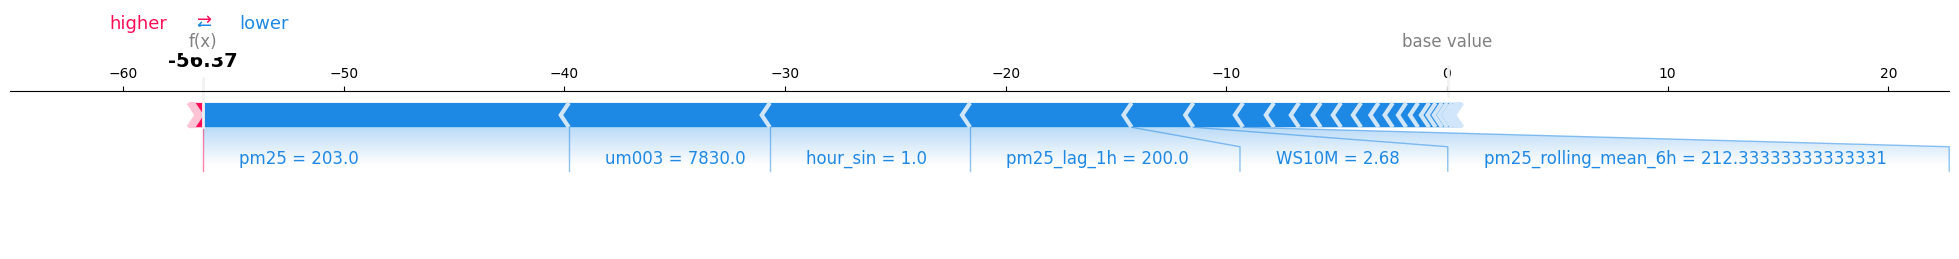

In [9]:
#Same for drops

drop_idx = y_delta_valid.idxmin()

print(f"Drop event: {dates_valid.iloc[drop_idx]}")
print(f"PM2.5 went from {current_pm25_valid.iloc[drop_idx]:.1f} to {y_absolute_valid.iloc[drop_idx]:.1f} "
      f"(actual change: {y_delta_valid.iloc[drop_idx]:.1f})")
print(f"Model's predicted change: {model.predict(X.iloc[[drop_idx]])[0]:+.1f}")

shap.force_plot(
    explainer.expected_value,
    shap_values[drop_idx],
    X.iloc[drop_idx],
    matplotlib=True,
    show=False,
)
plt.tight_layout()
plt.show()

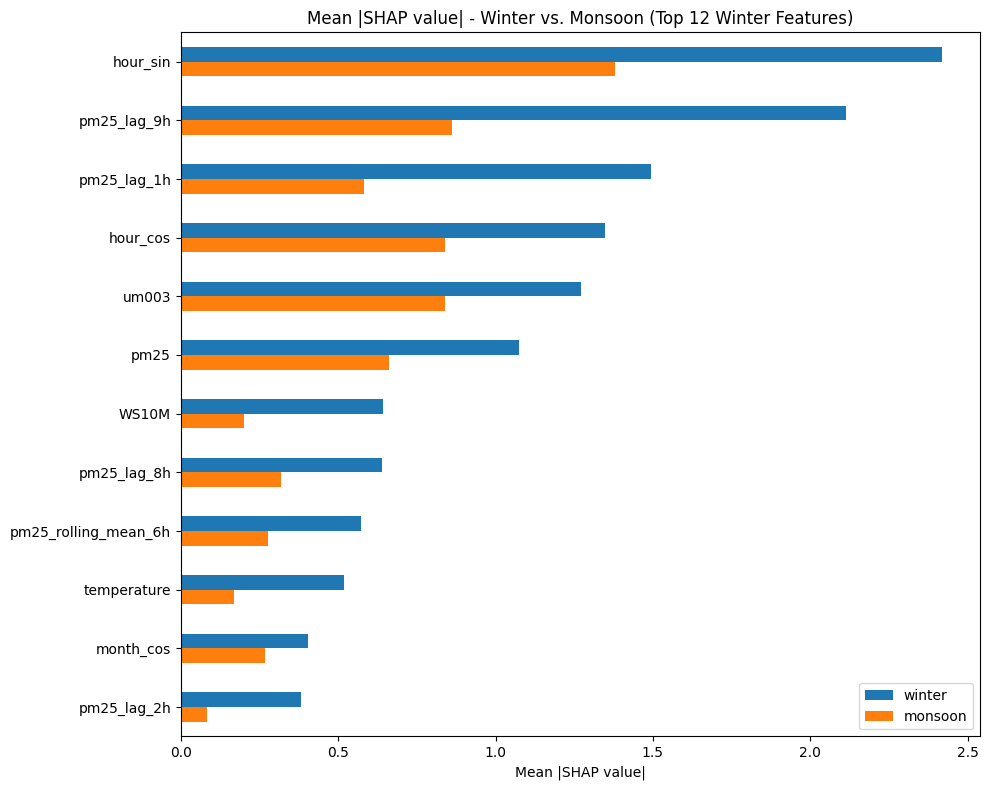

                        winter   monsoon
hour_sin              2.418304  1.381011
pm25_lag_9h           2.114963  0.861715
pm25_lag_1h           1.492813  0.582565
hour_cos              1.346983  0.838935
um003                 1.272746  0.840039
pm25                  1.074660  0.661795
WS10M                 0.642736  0.200175
pm25_lag_8h           0.640243  0.317029
pm25_rolling_mean_6h  0.570841  0.278243
temperature           0.519828  0.169351
month_cos             0.403377  0.266707
pm25_lag_2h           0.380857  0.084004


In [10]:
''' Seasonal comparison - winter vs. monsoon SHAP patterns
Splits predictions by season and compares mean |SHAP value| per feature, directly testing whether different factors drive PM2.5 changes in winter 
versus monsoon.
'''

winter_months = [12, 1, 2]   # December, January, February
monsoon_months = [6, 7, 8]   # June, July, August

winter_mask = df.loc[valid_mask, "month"].reset_index(drop=True).isin(winter_months)
monsoon_mask = df.loc[valid_mask, "month"].reset_index(drop=True).isin(monsoon_months)

winter_importance = pd.Series(np.abs(shap_values[winter_mask]).mean(axis=0), index=feature_columns)
monsoon_importance = pd.Series(np.abs(shap_values[monsoon_mask]).mean(axis=0), index=feature_columns)

seasonal_comparison = pd.DataFrame({
    "winter": winter_importance,
    "monsoon": monsoon_importance,
})
seasonal_comparison = seasonal_comparison.loc[
    seasonal_comparison.max(axis=1).sort_values(ascending=False).head(12).index
]

seasonal_comparison.plot(kind="barh", figsize=(10, 8))
plt.title("Mean |SHAP value| - Winter vs. Monsoon (Top 12 Winter Features)")
plt.xlabel("Mean |SHAP value|")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print(seasonal_comparison)

In [11]:
''' Seasonal share of importance
Mean |SHAP| per feature group within each season, divided by that season's total. Each column sums to 1, so seasons are compared by which drivers 
matter, not by how volatile PM2.5 is.
'''

month_valid = df.loc[valid_mask, "month"].reset_index(drop=True)
seasons = {"Winter (DJF)": [12, 1, 2], "Pre-monsoon (MAM)": [3, 4, 5], "Monsoon (JJAS)": [6, 7, 8, 9]}  # DJF = December, January, February; MAM = March, April, May; JJAS = June, July, August, September

season_share = pd.DataFrame({
    s: grouped[month_valid.isin(m)].abs().mean() / grouped[month_valid.isin(m)].abs().mean().sum()
    for s, m in seasons.items()
})
print(season_share.round(3))

                                       Winter (DJF)  Pre-monsoon (MAM)  \
Recent PM2.5 (current, lags, rolling)         0.412              0.281   
Particle count (um003)                        0.110              0.148   
Time of day                                   0.325              0.432   
Day of week                                   0.001              0.001   
Season                                        0.038              0.046   
Weather                                       0.111              0.089   
Station / data quality                        0.003              0.003   

                                       Monsoon (JJAS)  
Recent PM2.5 (current, lags, rolling)           0.100  
Particle count (um003)                          0.204  
Time of day                                     0.528  
Day of week                                     0.001  
Season                                          0.075  
Weather                                         0.090  
Station / data 


Since the two stations represent different pollution source types (waste transfer vs. traffic intersection), this checks whether SHAP reveals genuinely different drivers at each location.

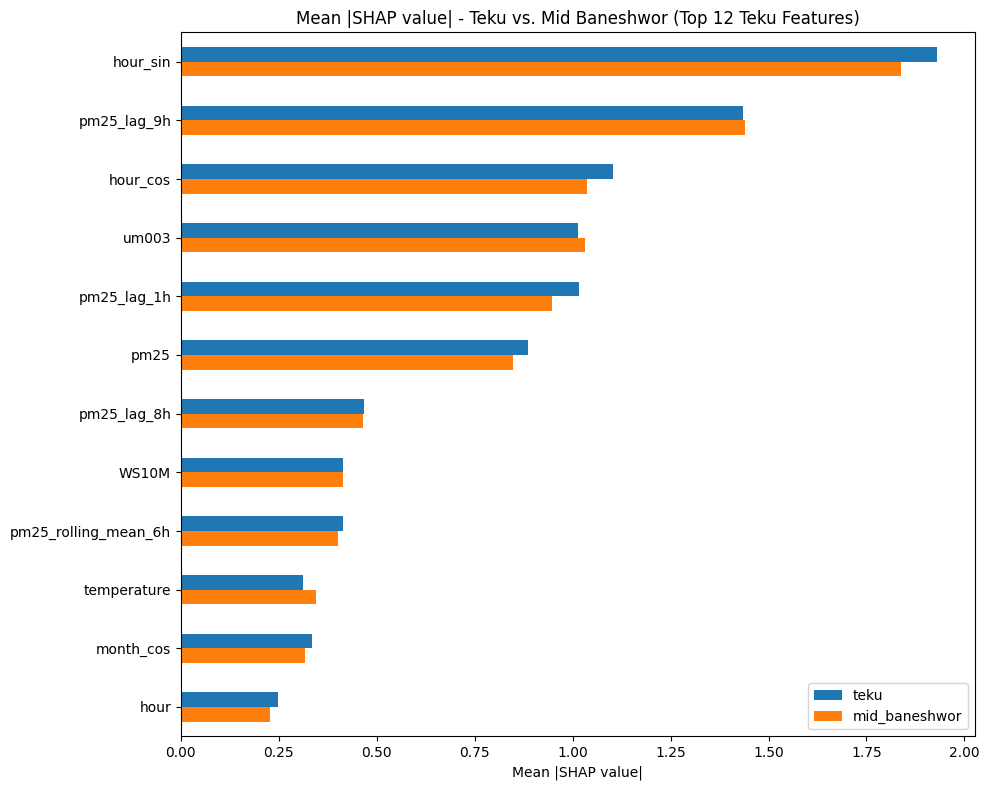

                          teku  mid_baneshwor
hour_sin              1.929778       1.838699
pm25_lag_9h           1.434526       1.440764
hour_cos              1.102129       1.036265
um003                 1.012690       1.030401
pm25_lag_1h           1.015094       0.948052
pm25                  0.885915       0.848146
pm25_lag_8h           0.467805       0.465555
WS10M                 0.413338       0.414833
pm25_rolling_mean_6h  0.412964       0.401379
temperature           0.312474       0.345386
month_cos             0.333801       0.316147
hour                  0.248225       0.228801


In [12]:
''' Station comparison - Teku vs. Mid Baneshwor
Since the two stations represent different pollution source types (waste transfer vs. traffic intersection), this checks whether SHAP reveals genuinely 
different drivers at each location.'''

teku_mask = df.loc[valid_mask, "station_teku"].reset_index(drop=True).astype(bool)
midb_mask = ~teku_mask

teku_importance = pd.Series(np.abs(shap_values[teku_mask]).mean(axis=0), index=feature_columns)
midb_importance = pd.Series(np.abs(shap_values[midb_mask]).mean(axis=0), index=feature_columns)

station_comparison = pd.DataFrame({
    "teku": teku_importance,
    "mid_baneshwor": midb_importance,
})
station_comparison = station_comparison.loc[
    station_comparison.max(axis=1).sort_values(ascending=False).head(12).index
]

station_comparison.plot(kind="barh", figsize=(10, 8))
plt.title("Mean |SHAP value| - Teku vs. Mid Baneshwor (Top 12 Teku Features)")
plt.xlabel("Mean |SHAP value|")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print(station_comparison)

In [13]:
## 10. Save SHAP values and summary.

import os

os.makedirs("../models", exist_ok=True)
np.save("../models/shap_values.npy", shap_values)

shap_summary = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_columns).sort_values(ascending=False)
shap_summary.to_csv("../models/shap_feature_importance.csv", header=["mean_abs_shap"])
season_share.to_csv("../models/shap_season_share.csv")

print("Saved SHAP values to ../models/shap_values.npy")
print("Saved feature importance ranking to ../models/shap_feature_importance.csv")
print("Saved seasonal share to ../models/shap_season_share.csv")
print()
print(shap_summary.head(15))

Saved SHAP values to ../models/shap_values.npy
Saved feature importance ranking to ../models/shap_feature_importance.csv
Saved seasonal share to ../models/shap_season_share.csv

hour_sin                1.887011
pm25_lag_9h             1.437453
hour_cos                1.071205
um003                   1.021007
pm25_lag_1h             0.983615
pm25                    0.868179
pm25_lag_8h             0.466748
WS10M                   0.414040
pm25_rolling_mean_6h    0.407524
temperature             0.327929
month_cos               0.325512
hour                    0.239104
pm25_lag_2h             0.234189
pm25_lag_7h             0.187477
relativehumidity        0.157283
dtype: float32
